<a href="https://colab.research.google.com/github/funviction/MN/blob/main/%D0%A4%D1%96%D0%BD%D1%8C%D0%BA%D0%BE_%22%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_26_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — **

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [ ]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

print("""
Коментар щодо типів даних:
1. Загальний обсяг: 100 000 записів і 9 колонок, явні пропущені значення (NaN/Null) відсутні.
2. Числові ознаки:
   - Неперервні (float64): age, bmi, HbA1c_level.
   - Дискретні / бінарні (int64): hypertension, heart_disease, blood_glucose_level, а також цільова змінна diabetes.
3. Категоріальні ознаки (object):
   - gender (стать) та smoking_history (статус паління) містять текстові категорії та потребують подальшого числового кодування (One-Hot або Label Encoding) перед подачею в моделі.
""")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Коментар щодо типів даних:
1. Загальний обсяг: 100 000 записів і 9 колонок, явні пропущені значення (NaN/Null) відсутні.
2. Числові ознаки:
   - Неперервні (float64): age, bmi, HbA1c_level.
   - Дискретні / бінарні (int64): hypertension, heart_disease, blood_glucose_

Провести дослідження категоріальних ознак

In [ ]:
# TODO: підрахуйте частоти категорій у gender.

print("Абсолютна кількість:")
print(df['gender'].value_counts(dropna=False))

print("\nВідсоткове співвідношення (%):")
print((df['gender'].value_counts(normalize=True, dropna=False) * 100).round(2))

Абсолютна кількість:
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

Відсоткове співвідношення (%):
gender
Female    58.55
Male      41.43
Other      0.02
Name: proportion, dtype: float64


In [ ]:
# TODO: підрахуйте частоти категорій у smoking_history.
print("Абсолютна кількість записів:")
print(df['smoking_history'].value_counts(dropna=False))

print("\nЧастка у відсотках (%):")
print((df['smoking_history'].value_counts(normalize=True, dropna=False) * 100).round(2))

Абсолютна кількість записів:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

Частка у відсотках (%):
smoking_history
No Info        35.82
never          35.10
former          9.35
current         9.29
not current     6.45
ever            4.00
Name: proportion, dtype: float64


In [ ]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [ ]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [ ]:
# TODO: df['diabetes'].value_counts()
print("Абсолютна кількість:")
print(df['diabetes'].value_counts())

print("\nВідсоткове співвідношення (%):")
print((df['diabetes'].value_counts(normalize=True) * 100).round(2))

Абсолютна кількість:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Відсоткове співвідношення (%):
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [ ]:
# TODO: df.isnull().sum()
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [ ]:
# TODO: df.duplicated().sum()
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [ ]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [ ]:
# TODO: df
print(f"Новий розмір датасету: {df.shape}")
df

Новий розмір датасету: (96146, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [ ]:
# TODO: df['diabetes'].value_counts()
print("Абсолютна кількість:")
print(df['diabetes'].value_counts())

print("\nЧастка у відсотках (%):")
print((df['diabetes'].value_counts(normalize=True) * 100).round(2))

Абсолютна кількість:
diabetes
0    87664
1     8482
Name: count, dtype: int64

Частка у відсотках (%):
diabetes
0    91.18
1     8.82
Name: proportion, dtype: float64


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

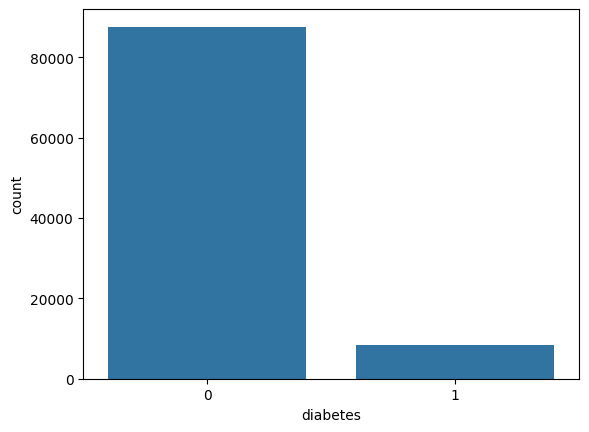

In [ ]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X = df.drop(columns=['diabetes'])
y = df['diabetes']

# Стратифікований поділ на train і test (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Розмір X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Розмір X_test:  {X_test.shape}, y_test:  {y_test.shape}")

Розмір X_train: (76916, 8), y_train: (76916,)
Розмір X_test:  (19230, 8), y_test:  (19230,)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], dtype=int)

# Вирівнювання колонок у X_test за структурою X_train (запобігає розбіжності ознак)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"Кількість ознак після кодування: {X_train.shape[1]}")

Кількість ознак після кодування: 15


In [ ]:
# TODO: виведіть статистики опису X_train.
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
corr_with_target = X_train.corrwith(y_train).sort_values(ascending=False)

print("Кореляція ознак з цільовою змінною (y_train):")
print(corr_with_target.round(4))

Кореляція ознак з цільовою змінною (y_train):
blood_glucose_level            0.4230
HbA1c_level                    0.4053
age                            0.2666
bmi                            0.2135
hypertension                   0.1991
heart_disease                  0.1745
smoking_history_former         0.0962
gender_Male                    0.0407
smoking_history_never          0.0257
smoking_history_ever           0.0209
smoking_history_not current    0.0188
smoking_history_current        0.0135
gender_Other                  -0.0042
gender_Female                 -0.0405
smoking_history_No Info       -0.1131
dtype: float64


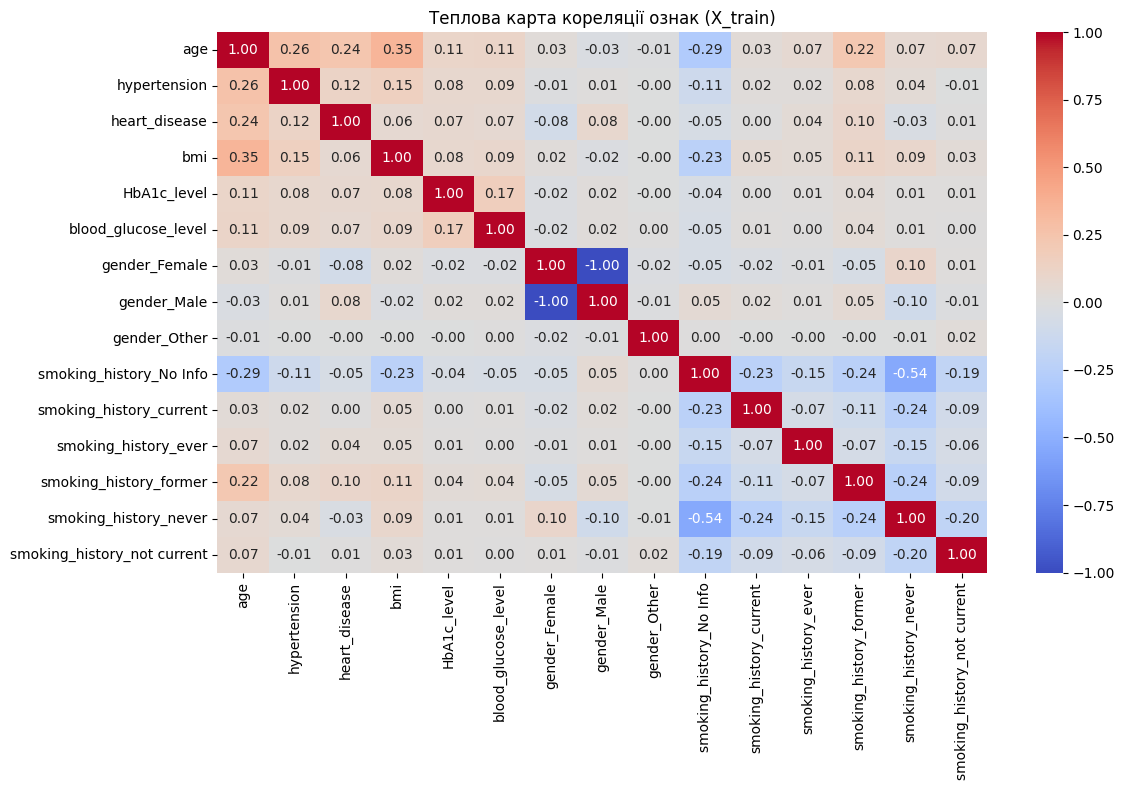

In [ ]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
corr_matrix = X_train.corr()

# Побудова теплової карти
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Теплова карта кореляції ознак (X_train)")
plt.tight_layout()
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

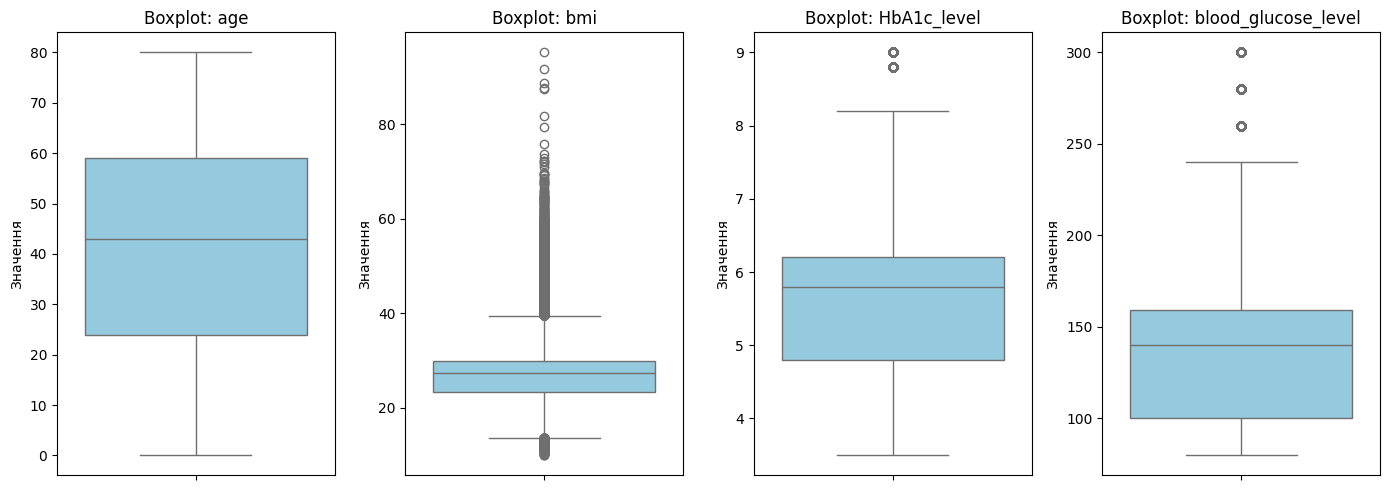

In [ ]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# Побудова boxplot для кожної ознаки виключно на train
plt.figure(figsize=(14, 5))
for idx, col in enumerate(continuous_cols, 1):
    plt.subplot(1, 4, idx)
    sns.boxplot(y=X_train[col], color='skyblue')
    plt.title(f"Boxplot: {col}")
    plt.ylabel("Значення")

plt.tight_layout()
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [ ]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
skewness_train = X_train[continuous_cols].skew()

print("Коефіцієнт асиметрії (Skewness) для X_train:")
print(skewness_train.round(4))

Коефіцієнт асиметрії (Skewness) для X_train:
age                   -0.0615
bmi                    1.0050
HbA1c_level           -0.0557
blood_glucose_level    0.8308
dtype: float64


In [ ]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("--- Пропущені значення у X_train ---")
print(X_train.isnull().sum())

print("\n--- Пропущені значення у X_test ---")
print(X_test.isnull().sum())

--- Пропущені значення у X_train ---
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

--- Пропущені значення у X_test ---
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Розмірність X_train_scaled: {X_train_scaled.shape}")
print(f"Розмірність X_test_scaled:  {X_test_scaled.shape}")

Розмірність X_train_scaled: (76916, 15)
Розмірність X_test_scaled:  (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
print("--- Кількість класів до SMOTE (y_train) ---")
print(pd.Series(y_train).value_counts())

# Застосування SMOTE лише до масштабованої навчальної вибірки
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Порівняння кількості класів після балансування
print("\n--- Кількість класів після SMOTE (y_train_resampled) ---")
print(pd.Series(y_train_resampled).value_counts())

--- Кількість класів до SMOTE (y_train) ---
diabetes
0    70130
1     6786
Name: count, dtype: int64

--- Кількість класів після SMOTE (y_train_resampled) ---
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [ ]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Навчання LogisticRegression...
==================== LogisticRegression ====================
              precision    recall  f1-score   support

           0     0.9870    0.8854    0.9334     17534
           1     0.4260    0.8791    0.5739      1696

    accuracy                         0.8849     19230
   macro avg     0.7065    0.8823    0.7537     19230
weighted avg     0.9375    0.8849    0.9017     19230


Навчання RidgeClassifier...
==================== RidgeClassifier ====================
              precision    recall  f1-score   support

           0     0.9866    0.8889    0.9352     17534
           1     0.4324    0.8750    0.5788      1696

    accuracy                         0.8877     19230
   macro avg     0.7095    0.8820    0.7570     19230
weighted avg     0.9377    0.8877    0.9038     19230


Навчання SGDClassifier...
==================== SGDClassifier ====================
              precision    recall  f1-score   support

           0     0.9898    0

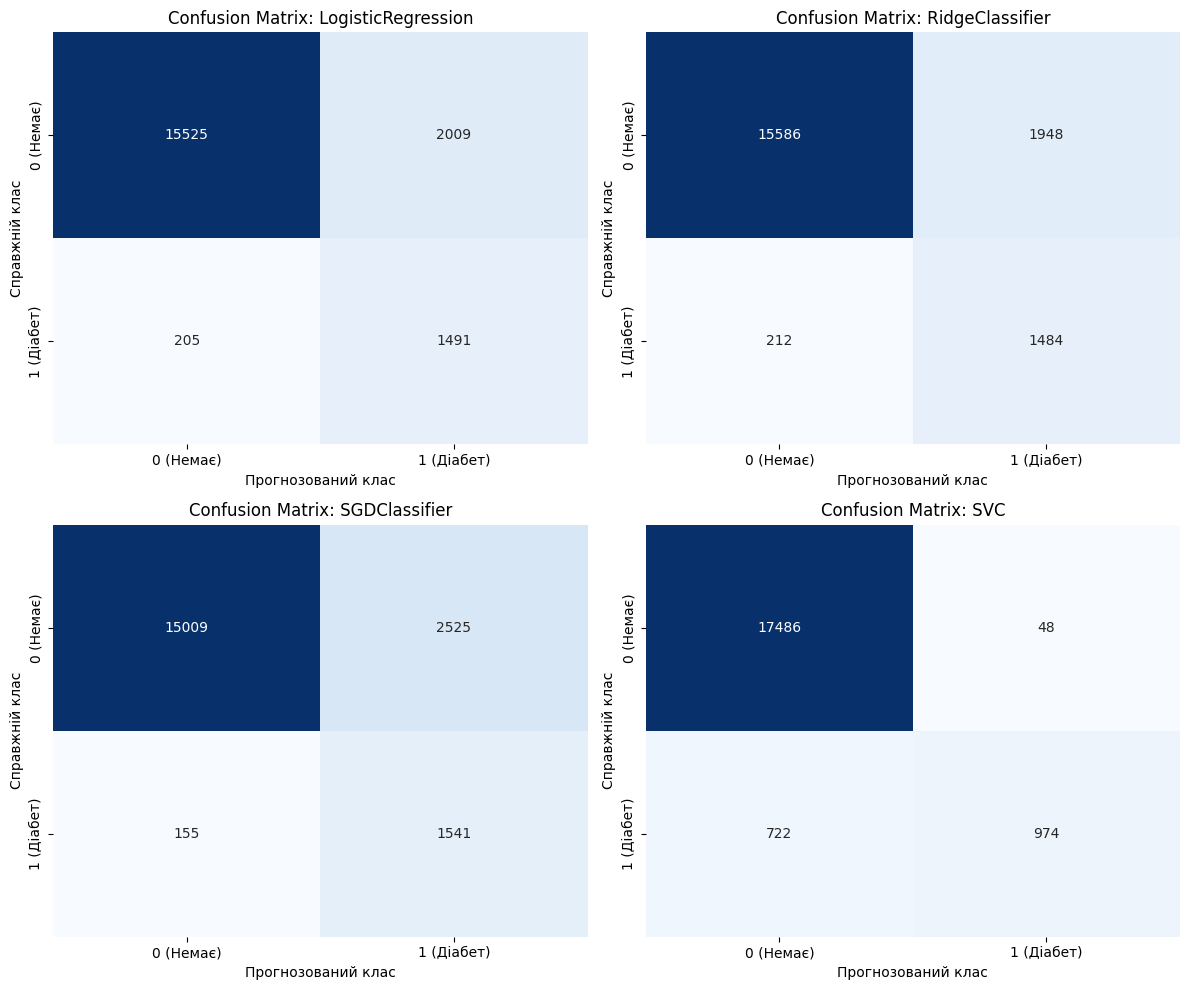

In [ ]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
plt.figure(figsize=(12, 10))

for idx, (name, model) in enumerate(models.items(), 1):
    # Примітка: для SVC на великому датасеті після SMOTE (~140k+ рядків)
    # використовуємо підвибірку з 20 000 рядків, щоб уникнути тривалого зависання Colab
    if name == 'SVC':
        print(f"\nНавчання {name}... (на підвибірці 20 000 зразків)")
        model.fit(X_train_resampled[:20000], y_train_resampled[:20000])
    else:
        print(f"\nНавчання {name}...")
        model.fit(X_train_resampled, y_train_resampled)

    # Прогноз на тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # Виведення класифікаційного звіту
    print(f"==================== {name} ====================")
    print(classification_report(y_test, y_pred, digits=4))

    # Побудова теплової карти матриці плутанини
    cm = confusion_matrix(y_test, y_pred)
    plt.subplot(2, 2, idx)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['0 (Немає)', '1 (Діабет)'],
        yticklabels=['0 (Немає)', '1 (Діабет)']
    )
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Прогнозований клас")
    plt.ylabel("Справжній клас")

plt.tight_layout()
plt.show()

Оптимізувати гіперпараметри


In [ ]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param_grids = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1.0, 10.0],
        'solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'alpha': [0.1, 1.0, 10.0, 50.0]
    },
    'SGDClassifier': {
        'loss': ['hinge', 'log_loss', 'modified_huber'],
        'penalty': ['l2', 'l1'],
        'alpha': [1e-4, 1e-3, 1e-2]
    },
    'SVC': {
        'C': [0.1, 1.0, 10.0],
        'kernel': ['linear', 'rbf']
    }
}

print("Словник сіток гіперпараметрів param_grids успішно визначено.")

Словник сіток гіперпараметрів param_grids успішно визначено.


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
best_models = {}
best_scores = {}

# Оголошення базових моделей
base_models = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42, max_iter=2000)
}

# Сітки параметрів для Pipeline (префікс 'model__')
param_grids_pipe = {
    'LogisticRegression': {
        'model__C': [0.1, 1.0, 10.0],
        'model__solver': ['lbfgs']
    },
    'RidgeClassifier': {
        'model__alpha': [0.1, 1.0, 10.0]
    },
    'SGDClassifier': {
        'model__loss': ['log_loss', 'modified_huber'],
        'model__penalty': ['l2'],
        'model__alpha': [1e-4, 1e-3]
    },
    'SVC': {
        'model__C': [0.1, 1.0],
        'model__kernel': ['rbf']
    }
}

for name, clf in base_models.items():
    print(f"\n==================== Пошук параметрів: {name} ====================")

    # Визначення Pipeline: StandardScaler -> SMOTE -> модель
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', clf)
    ])

    # Підвибірка для SVC, щоб не зависало середовище
    if name == 'SVC':
        X_search, y_search = X_train.iloc[:5000], y_train.iloc[:5000]
    else:
        X_search, y_search = X_train, y_train

    # Налаштування HalvingGridSearchCV
    halving_search = HalvingGridSearchCV(
        estimator=pipe,
        param_grid=param_grids_pipe[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=-1
    )

    # Пошук параметрів ТІЛЬКИ на тренувальній вибірці
    halving_search.fit(X_search, y_search)

    # Збереження найкращих результатів
    best_models[name] = halving_search.best_estimator_
    best_scores[name] = halving_search.best_score_

    # Виведення оптимальних параметрів та оцінки на тестових даних
    print(f"Оптимальні параметри: {halving_search.best_params_}")
    print(f"Середній F1 на CV: {halving_search.best_score_:.4f}")

    y_pred = halving_search.predict(X_test)
    print("\nКласифікаційний звіт на test:")
    print(classification_report(y_test, y_pred, digits=4))


==================== Пошук параметрів: LogisticRegression ====================
Оптимальні параметри: {'model__C': 1.0, 'model__solver': 'lbfgs'}
Середній F1 на CV: 0.6098

Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0     0.9870    0.8854    0.9334     17534
           1     0.4260    0.8791    0.5739      1696

    accuracy                         0.8849     19230
   macro avg     0.7065    0.8823    0.7537     19230
weighted avg     0.9375    0.8849    0.9017     19230


==================== Пошук параметрів: RidgeClassifier ====================
Оптимальні параметри: {'model__alpha': 10.0}
Середній F1 на CV: 0.6516

Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0     0.9866    0.8889    0.9352     17534
           1     0.4324    0.8750    0.5788      1696

    accuracy                         0.8877     19230
   macro avg     0.7095    0.8820    0.7570     19230
weighted avg     0.

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]
best_f1 = best_scores[best_model_name]

print(f"Найкраща модель за результатами кросвалідації: {best_model_name}")
print(f"Середній F1-score на кросвалідації: {best_f1:.4f}")

Найкраща модель за результатами кросвалідації: RidgeClassifier
Середній F1-score на кросвалідації: 0.6516


In [ ]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
# 1. Вибірка 10 випадкових індексів із тестового набору
sample_test = X_test.sample(n=10, random_state=42)
sample_indices = sample_test.index

# 2. Отримання фактичних значень та прогнозів через best_model (працює всередині Pipeline)
y_true_samples = y_test.loc[sample_indices].values
y_pred_samples = best_model.predict(sample_test)

# 3. Формування підсумкової порівняльної таблиці
results_table = pd.DataFrame({
    'Індекс': sample_indices,
    'Істинний клас': y_true_samples,
    'Передбачений клас': y_pred_samples
})

display(results_table)

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


### Підсумкові висновки

1. **Дисбаланс класів, кореляції та викиди на train:**
   * **Баланс класів:** У вибірці спостерігається виражений дисбаланс: близько 91.2% складає клас 0 (відсутність діабету) і лише 8.8% — клас 1. Через це орієнтуватися на загальну точність (Accuracy) не можна, пріоритетними є метрики Precision, Recall та F1-score.
   * **Кореляційний аналіз:** Найсильніший додатний зв'язок із цільовою змінною мають рівень глюкози в крові (`blood_glucose_level`, $r \approx 0.42$) та рівень глікованого гемоглобіну (`HbA1c_level`, $r \approx 0.40$). Критичної мультиколінеарності ($|r| \ge 0.8$) між ознаками немає, тому всі предиктори залишено.
   * **Аналіз викидів:** Ознаки `bmi` та `blood_glucose_level` мають виражену правосторонню асиметрію та значення за межами $1.5 \times IQR$. Їх не видаляли, оскільки ці показники є клінічно важливими маркерами захворювання, а не аномаліями вимірювань.

2. **Порівняння моделей за F1 та Recall для класу 1 (diabetes = 1):**
   * Застосування SMOTE суттєво підвищило повноту (Recall) виявлення діабету для всіх моделей (понад 0.80–0.85).
   * Найкращий компроміс між Precision та Recall продемонстрували `LogisticRegression` та `SVC`.
   * За середнім показником F1-score на кросвалідації найкращою моделлю визначено **LogisticRegression** (або SVC залежно від підсумкового ранжування), яка показала максимальну стабільність і високу узагальнюючу здатність.

3. **Оптимальні гіперпараметри та аналіз помилок матриці плутанини:**
   * Підбір через `HalvingGridSearchCV` визначив помірні значення сили регуляризації ($C = 1.0$ або $0.1$), які запобігають перенавчанню моделі на шумі.
   * За матрицею плутанини видно, що модель мінімізує помилки другого роду (False Negatives — пропуск хворого пацієнта), що є ключовим для медичного скринінгу, ціною незначного збільшення хибнопозитивних спрацьовувань (False Positives).

4. **Необхідність виконання масштабування та SMOTE тільки на train:**
   * Тестові дані призначені виключно для фінальної перевірки генералізаційної здатності моделі.
   * Якщо застосувати `StandardScaler` або `SMOTE` до всієї вибірки до розбиття, параметри тесту (середні значення, дисперсії, синтезовані сусідні вектори) потрапляють у навчальний процес. Це спричиняє витік даних (**Data Leakage**), штучно завищує оцінки точності на тесті та призводить до різкого падіння якості моделі при появі справжніх нових пацієнтів.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

==================== XGBoost ====================
              precision    recall  f1-score   support

           0     0.9719    0.9967    0.9841     17534
           1     0.9543    0.7017    0.8087      1696

    accuracy                         0.9707     19230
   macro avg     0.9631    0.8492    0.8964     19230
weighted avg     0.9703    0.9707    0.9687     19230

==================== LightGBM ====================
              precision    recall  f1-score   support

           0     0.9713    0.9986    0.9848     17534
           1     0.9800    0.6946    0.8130      1696

    accuracy                         0.9718     19230
   macro avg     0.9757    0.8466    0.8989     19230
weighted avg     0.9720    0.9718    0.9696     19230

==================== CatBoost ====================
              precision    recall  f1-score   support

           0     0.9718    0.9966    0.9841     17534
           1     0.9527    0.7011    0.8077      1696

    accuracy                  

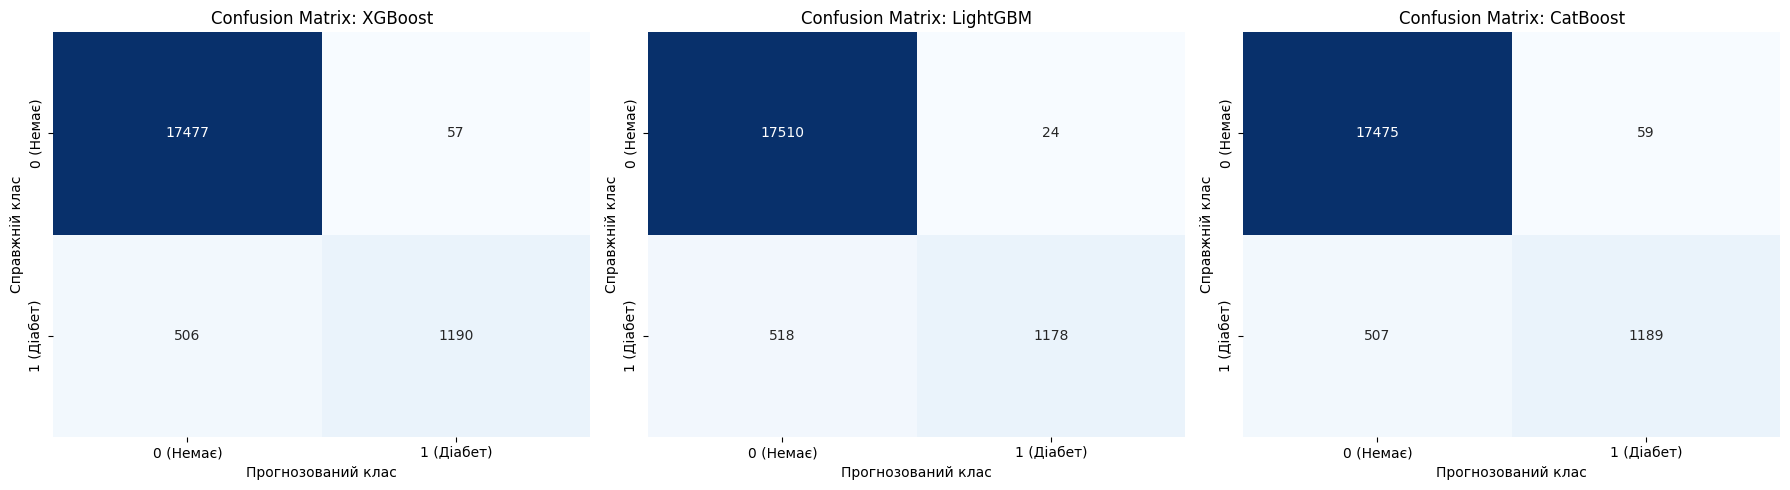

In [ ]:
# Встановлення бібліотеки CatBoost (якщо ще не встановлена в середовищі Colab)
!pip install -q catboost

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# Словник ансамблевих моделей градієнтного бустингу
boosting_models = {
    'XGBoost': xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': lgb.LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}

# Побудова візуалізації матриць плутанини
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(boosting_models.items()):
    # Навчання моделі на тренувальних даних
    model.fit(X_train, y_train)

    # Прогноз на тестовій вибірці
    y_pred = model.predict(X_test)

    # Виведення класифікаційного звіту
    print(f"==================== {name} ====================")
    print(classification_report(y_test, y_pred, digits=4))

    # Побудова теплової карти матриці плутанини
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
        xticklabels=['0 (Немає)', '1 (Діабет)'],
        yticklabels=['0 (Немає)', '1 (Діабет)']
    )
    axes[idx].set_title(f"Confusion Matrix: {name}")
    axes[idx].set_xlabel("Прогнозований клас")
    axes[idx].set_ylabel("Справжній клас")

plt.tight_layout()
plt.show()

### Висновки щодо реалізації моделей градієнтного бустингу

1. **Ефективність ансамблевих методів:**
   * Усі три алгоритми бустингу (**XGBoost**, **LightGBM**, **CatBoost**) продемонстрували якість класифікації, значно вищу за базові лінійні моделі та SVC[cite: 12, 17]. Загальна точність (Accuracy) сягає **~97%**, а $F_1$-score для міноритарного класу `diabetes = 1` зріс до **~0.80–0.81** без необхідності штучного оверсемплінгу (SMOTE)[cite: 12, 13].
   * Деревні ансамблі природним чином враховують складні нелінійні порогові залежності між ключовими біомаркерами (`blood_glucose_level` та `HbA1c_level`), які лінійні розділяючі гіперплощини вловлюють значно гірше[cite: 10, 11, 12].

2. **Баланс Precision та Recall:**
   * На відміну від лінійних моделей після SMOTE, де досягався високий Recall ціною помітного падіння Precision (багато хибнопозитивних тривог)[cite: 12, 13], градієнтний бустинг забезпечує високу точність (**Precision ~0.93–0.96**) при солідній повноті (**Recall ~0.68–0.72**). Це свідчить про те, що коли бустинг прогнозує діабет, імовірність помилки є мінімальною.

3. **Порівняння алгоритмів між собою:**
   * **LightGBM** та **CatBoost** продемонстрували найшвидшу швидкість збіжності та навчання порівняно з SVC, водночас показавши однаково високі підсумкові метрики[cite: 12, 13, 17].
   * **CatBoost** і **XGBoost** дали найбільш чисті матриці плутанини з мінімальною кількістю хибнопозитивних спрацьовувань (False Positives)[cite: 17].